# Planificador geoespacial de observacion de eclipses

Este notebook prototipa la Idea 3 de `01_ideas_producto.md`: dado un eclipse y una zona de interes, busca ubicaciones de observacion y las compara por duracion de totalidad, climatologia de nubosidad y accesibilidad. Para las ubicaciones mejor puntuadas, incorpora hoteles y rutas como capas logisticas exploratorias.

**Pregunta:** para un eclipse y una region elegidos, donde conviene observarlo y que opciones cercanas hay para alojarse y llegar?

**Objetivo modelable:** estimar la probabilidad climatologica de cielo razonablemente despejado durante la hora local del eclipse; combinarla con circunstancias astronomicas y accesibilidad en una recomendacion explicable. La nubosidad historica no es un pronostico del evento. La decision final debe actualizarse con pronosticos meteorologicos operativos dias antes.

**Alcance de este prototipo:** el usuario configura el evento mediante la URL de la tabla de trayectoria NASA y define candidatos o puntos de interes dentro de la zona donde viajaria. Se usa el eclipse del 2 de agosto de 2027 como ejemplo editable, no como limite funcional. El pipeline actual esta preparado para eclipses solares totales con trayectoria central NASA; eclipses lunares o parciales necesitan una geometria de visibilidad distinta. La cobertura geografica, hoteles y rutas dependen de las fuentes disponibles para la region seleccionada.

**Limitaciones:** la duracion fuera de la linea central es aproximada; la nubosidad reanalizada representa climatologia, no certeza futura; aeropuertos y OpenStreetMap son proxies parciales de accesibilidad y alojamiento. No se recomienda un modelo supervisado complejo sin datos suficientes y validacion temporal/espacial. Los pesos son decisiones de producto que deben probarse con usuarios.

## 1. Entorno y configuracion

Dependencias ligeras; no se requieren paquetes GIS. La descarga de fuentes es en vivo y puede depender de disponibilidad de red.

In [21]:
# Si falta alguna dependencia, descomenta y ejecuta esta celda.
# %pip install requests pandas numpy matplotlib scikit-learn beautifulsoup4

from pathlib import Path
import re
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from IPython.display import display
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

SEED = 42
# Ejemplo editable. Para otro eclipse, cambia fecha y URL por su tabla de trayectoria NASA.
EVENT_DATE = "2027-08-02"
ECLIPSE_PATH_URL = "https://eclipse.gsfc.nasa.gov/SEpath/SEpath2001/SE2027Aug02Tpath.html"
EVENT_YEAR = int(EVENT_DATE[:4])
HISTORICAL_YEARS = range(max(1940, EVENT_YEAR - 30), EVENT_YEAR)
CLIMATE_START_YEAR = HISTORICAL_YEARS.start
CLIMATE_END_YEAR = HISTORICAL_YEARS.stop - 1
MIN_VALID_YEARS = 15
CLEAR_CLOUD_THRESHOLD = 20.0
OPEN_METEO_URL = "https://archive-api.open-meteo.com/v1/archive"
OURAIRPORTS_URL = "https://raw.githubusercontent.com/davidmegginson/ourairports-data/main/airports.csv"
OVERPASS_URL = "https://overpass-api.de/api/interpreter"
OSRM_URL = "https://router.project-osrm.org/route/v1/driving"
REQUEST_TIMEOUT = 45
SESSION = requests.Session()
SESSION.headers.update({"User-Agent": "TFM-Eclipse-Planning-Notebook/1.0 (academic research)"})

print(f"Evento seleccionado: {EVENT_DATE}")
print(f"Ventana climatologica disponible para el ejemplo: {CLIMATE_START_YEAR}-{CLIMATE_END_YEAR}")

Evento seleccionado: 2027-08-02
Ventana climatologica disponible para el ejemplo: 1997-2026


## 2. Leer `01_ideas_producto.md` y extraer el objetivo

El archivo aporta el problema, los usuarios y los criterios de valor. El notebook extrae la descripcion de la Idea 3, pero deriva el target estadistico desde los datos y la configuracion elegida: el documento no prescribe un algoritmo de prediccion ni un umbral meteorologico.

In [22]:
def find_proposal_file():
    candidates = [
        Path.cwd() / "docs" / "entregas" / "01_ideas_producto.md",
        Path.cwd() / "01_ideas_producto.md",
        Path.cwd().parent / "01_ideas_producto.md",
    ]
    for candidate in candidates:
        if candidate.exists():
            return candidate
    raise FileNotFoundError(
        "No encuentro docs/entregas/01_ideas_producto.md. "
        "Ejecuta el notebook desde la raiz del repositorio."
    )

proposal_path = find_proposal_file()
proposal_text = proposal_path.read_text(encoding="utf-8")
idea_match = re.search(
    r"(?ms)^# Idea 3 - Planificador Geoespacial de Observaci.n de Eclipses\s*$"
    r"(.*?)(?=^# Idea \d+ -|\Z)",
    proposal_text,
)
if not idea_match:
    raise ValueError(f"No se encontro la Idea 3 esperada en {proposal_path}.")
idea_text = idea_match.group(1)
sections = {
    title.strip(): body.strip()
    for title, body in re.findall(
        r"(?ms)^## (.+?)\s*\n(.*?)(?=^## |\Z)", idea_text
    )
}
print(f"Documento: {proposal_path}")
for section_name in ["Problema que resuelve", "Qué decisión, proceso o situación podría mejorar con datos"]:
    matching_key = next((key for key in sections if key.casefold() == section_name.casefold()), None)
    if matching_key:
        print(f"\n{matching_key}\n{sections[matching_key]}")

TARGET_DEFINITION = {
    "decision": "elegir ubicacion de observacion y planificar alojamiento y desplazamiento",
    "target_climatico": f"cloud_cover <= {CLEAR_CLOUD_THRESHOLD}% durante la hora local aproximada del eclipse",
    "unit_of_analysis": "ubicacion candidata x eclipse seleccionado",
    "event": EVENT_DATE,
    "climate_window": f"hasta 30 anos previos al evento, limitado por la cobertura del reanalisis",
    "geography": "region definida por la trayectoria del eclipse y las ubicaciones candidatas configuradas",
}
pd.Series(TARGET_DEFINITION, name="Definicion adoptada")

Documento: e:\Programming\Master\Proyecto_TFM\docs\entregas\01_ideas_producto.md

Problema que resuelve
* **Qué ocurre actualmente:** Muchas personas interesadas en observar eclipses solares o lunares consultan mapas, artículos, foros y herramientas dispersas para saber desde qué ubicaciones se verá mejor un fenómeno concreto, con qué recorrido y con qué probabilidad de cielo despejado.
* **Por qué supone un problema:** La información relevante suele estar fragmentada y no siempre es fácil traducirla a una decisión práctica: dónde ir, cuándo desplazarse, cuánto esperar de visibilidad o qué punto ofrece la mejor combinación entre duración, cobertura y meteorología.
* **Qué decisión, proceso o situación podría mejorar con datos:** Se mejoraría la planificación de viajes y observaciones astronómicas mediante recomendaciones de ubicaciones óptimas para ver eclipses futuros, por ejemplo el de 2027, combinando trazado de la sombra, duración del evento, accesibilidad y condiciones climáticas 

decision            elegir ubicacion de observacion y planificar a...
target_climatico    cloud_cover <= 20.0% durante la hora local apr...
unit_of_analysis           ubicacion candidata x eclipse seleccionado
event                                                      2027-08-02
climate_window      hasta 30 anos previos al evento, limitado por ...
geography           region definida por la trayectoria del eclipse...
Name: Definicion adoptada, dtype: str

## 3. Evento, zona de interes y objetivo modelable

La URL de trayectoria identifica el eclipse; la fecha fija el dia del evento y la ventana climatica. Para otro evento hay que actualizar ambas. `REGION_BOUNDS` limita el tramo de trayectoria que se analizara. Las ciudades son ejemplos editables y se pueden sustituir por ubicaciones obtenidas de un geocodificador o por lugares que aporte el usuario.

La variable principal es la cobertura nubosa horaria en la hora UTC aproximada del maximo local. `cloud_cover <= 20%` se usa como etiqueta proxy de cielo relativamente despejado, no como garantia de observacion.

In [23]:
# Bounding box (south, west, north, east); edit this for the selected eclipse/region.
REGION_BOUNDS = (33.0, -8.0, 38.0, 1.0)

# Illustrative destinations for the 2027 Iberian example. Replace for another region.
CANDIDATE_PLACES = [
    {"name": "Tarifa", "latitude": 36.0131, "longitude": -5.6044},
    {"name": "Cadiz", "latitude": 36.5271, "longitude": -6.2886},
    {"name": "Algeciras", "latitude": 36.1408, "longitude": -5.4562},
    {"name": "Malaga", "latitude": 36.7213, "longitude": -4.4214},
    {"name": "Almeria", "latitude": 36.8340, "longitude": -2.4637},
    {"name": "Gibraltar", "latitude": 36.1408, "longitude": -5.3536},
    {"name": "Tangier", "latitude": 35.7595, "longitude": -5.8340},
    {"name": "Tetouan", "latitude": 35.5889, "longitude": -5.3626},
    {"name": "Melilla", "latitude": 35.2923, "longitude": -2.9381},
]

ORIGIN = None  # Example: {"latitude": 40.4168, "longitude": -3.7038}
HOTEL_SEARCH_RADIUS_M = 25000

TARGET_DEFINITION.update({
    "event": EVENT_DATE,
    "geography": f"bounding box {REGION_BOUNDS}; editable destination list",
    "training_window": f"historical dates matching the event month/day in {CLIMATE_START_YEAR}-{CLIMATE_END_YEAR}",
})
pd.Series(TARGET_DEFINITION, name="Configuracion del caso")

decision            elegir ubicacion de observacion y planificar a...
target_climatico    cloud_cover <= 20.0% durante la hora local apr...
unit_of_analysis           ubicacion candidata x eclipse seleccionado
event                                                      2027-08-02
climate_window      hasta 30 anos previos al evento, limitado por ...
geography           bounding box (33.0, -8.0, 38.0, 1.0); editable...
training_window     historical dates matching the event month/day ...
Name: Configuracion del caso, dtype: str

## 4. Comparar fuentes de datos

Puntuacion exploratoria 1-5 (5 es mejor), definida para este caso de uso; no son metricas oficiales. La trayectoria por evento suele ser mas util que un catalogo general para resolver circunstancias locales. Los criterios de licencia y cobertura deben revisarse para la region y uso final.

In [24]:
source_scores = pd.DataFrame([
    {"Fuente": "NASA GSFC: tabla de trayectoria por evento", "Cobertura": 5, "Resolucion": 5, "Calidad": 5, "Acceso": 4, "Licencia/datos": 4, "Actualizacion": 3},
    {"Fuente": "NASA GSFC: catalogos de eclipses", "Cobertura": 5, "Resolucion": 2, "Calidad": 5, "Acceso": 4, "Licencia/datos": 4, "Actualizacion": 3},
    {"Fuente": "USNO: datos de eclipses", "Cobertura": 3, "Resolucion": 3, "Calidad": 5, "Acceso": 3, "Licencia/datos": 4, "Actualizacion": 3},
    {"Fuente": "Open-Meteo / ERA5: reanalisis horario", "Cobertura": 5, "Resolucion": 3, "Calidad": 4, "Acceso": 5, "Licencia/datos": 3, "Actualizacion": 4},
    {"Fuente": "OpenStreetMap: POI y red vial", "Cobertura": 5, "Resolucion": 4, "Calidad": 3, "Acceso": 4, "Licencia/datos": 3, "Actualizacion": 4},
])
score_columns = ["Cobertura", "Resolucion", "Calidad", "Acceso", "Licencia/datos", "Actualizacion"]
source_scores["Puntuacion media"] = source_scores[score_columns].mean(axis=1).round(2)
display(source_scores.sort_values("Puntuacion media", ascending=False))

,Fuente,Cobertura,Resolucion,Calidad,Acceso,Licencia/datos,Actualizacion,Puntuacion media
0,NASA GSFC: tabla de trayectoria por evento,5,5,5,4,4,3,4.33
3,Open-Meteo / ERA5: reanalisis horario,5,3,4,5,3,4,4.00
1,NASA GSFC: catalogos de eclipses,5,2,5,4,4,3,3.83
4,OpenStreetMap: POI y red vial,5,4,3,4,3,4,3.83
2,USNO: datos de eclipses,3,3,5,3,4,3,3.50


## 5. Fuentes seleccionadas

**Astronomia:** NASA GSFC, tabla de trayectoria del eclipse seleccionado. Contiene linea central, limites, ancho y duracion de totalidad. Atribucion requerida: “Eclipse Predictions by Fred Espenak, NASA's GSFC”. El catalogo ayuda a descubrir eventos; para el analisis local se necesita la tabla del evento concreto.

**Meteorologia:** Open-Meteo Historical Weather API, variable horaria `cloud_cover` de ERA5. Es global, no requiere clave para uso no comercial y proporciona reanalisis historico; consultar terminos y atribucion de Open-Meteo/ECMWF antes de publicar o usar comercialmente. No representa el pronostico del evento.

**Alojamiento y red vial:** OpenStreetMap mediante Overpass para puntos etiquetados como alojamiento y OSRM como demostracion de ruteo sobre datos OSM. La cobertura y etiquetas varian; respetar atribucion OSM y limites de los servicios publicos.

**Complementos para producto real:** GTFS o proveedores locales para transporte publico; red vial y restricciones; disponibilidad y precio de alojamiento mediante acuerdos/licencias validos; aforo, accesibilidad, elevacion, permisos y pronostico oficial. No se debe hacer scraping de plataformas de reservas sin permiso.

## 6. Descargar y versionar la trayectoria

Se consulta la tabla HTML del evento seleccionado, se extrae la linea central y se guarda una copia CSV fechada. La tabla NASA indica coordenadas WGS84 y publica puntos de la trayectoria central a intervalos de dos minutos. Se conserva la URL y la fecha de descarga como metadatos.

In [25]:
from bs4 import BeautifulSoup


def dms_to_decimal(degrees, minutes, hemisphere):
    value = float(degrees) + float(minutes) / 60.0
    return -value if hemisphere in {"S", "W"} else value


def parse_nasa_path_table(url):
    response = SESSION.get(url, timeout=REQUEST_TIMEOUT)
    response.raise_for_status()
    soup = BeautifulSoup(response.content, "html.parser")
    row_texts = []
    for pre in soup.find_all("pre"):
        row_texts.extend(pre.get_text("\n").splitlines())
    for row in soup.find_all("tr"):
        row_texts.append(" ".join(row.stripped_strings))

    time_pattern = re.compile(r"^\s*(\d{2}):(\d{2})\s+(.+)$")
    coordinate_pattern = re.compile(
        r"(\d{1,2})\s+(\d{1,2}(?:\.\d+)?)([NS])\s+"
        r"(\d{1,3})\s+(\d{1,2}(?:\.\d+)?)([EW])"
    )
    duration_pattern = re.compile(r"(\d{1,2})m(\d{2}(?:\.\d+)?)s")
    parsed_rows = []
    for row in row_texts:
        time_match = time_pattern.match(row)
        duration_match = duration_pattern.search(row)
        coordinates = list(coordinate_pattern.finditer(row))
        if not time_match or not duration_match or len(coordinates) < 3:
            continue
        central = coordinates[2]
        central_values = central.groups()
        width_values = re.findall(
            r"\d+(?:\.\d+)?", row[coordinates[-1].end():duration_match.start()]
        )
        if not width_values:
            continue
        hours, minutes = map(int, time_match.groups()[:2])
        duration_minutes = int(duration_match.group(1))
        duration_seconds = float(duration_match.group(2))
        parsed_rows.append({
            "time_utc": hours * 60 + minutes,
            "latitude": dms_to_decimal(*central_values[:3]),
            "longitude": dms_to_decimal(*central_values[3:]),
            "duration_center_s": duration_minutes * 60 + duration_seconds,
            "path_width_km": float(width_values[-1]),
        })

    path = pd.DataFrame(parsed_rows).drop_duplicates("time_utc").sort_values("time_utc")
    if len(path) < 3:
        raise ValueError(
            "No se pudieron interpretar al menos tres filas de la trayectoria NASA. "
            f"Comprueba el formato y la URL: {url}"
        )
    return path.reset_index(drop=True)


try:
    path_df = parse_nasa_path_table(ECLIPSE_PATH_URL)
except (requests.RequestException, ValueError) as error:
    raise RuntimeError(f"No se pudo cargar la trayectoria del eclipse elegido: {error}") from error

PROJECT_ROOT = proposal_path.parents[2]
RAW_DATA_DIR = PROJECT_ROOT / "data" / "raw"
RAW_DATA_DIR.mkdir(parents=True, exist_ok=True)
path_file = RAW_DATA_DIR / f"eclipse_path_{EVENT_DATE}.csv"
path_df.to_csv(path_file, index=False)
path_metadata = pd.DataFrame([{
    "event_date": EVENT_DATE,
    "source_url": ECLIPSE_PATH_URL,
    "downloaded_utc": pd.Timestamp.now(tz="UTC").isoformat(),
    "rows": len(path_df),
    "attribution": "Eclipse Predictions by Fred Espenak, NASA's GSFC",
}])
path_metadata.to_json(path_file.with_suffix(".metadata.json"), orient="records", indent=2)
print(f"{len(path_df)} puntos de trayectoria guardados en {path_file}")
display(path_df.head())

101 puntos de trayectoria guardados en e:\Programming\Master\Proyecto_TFM\data\raw\eclipse_path_2027-08-02.csv


,time_utc,latitude,longitude,duration_center_s,path_width_km
0,506,30.488333,-36.233333,204.6,213.0
1,508,32.118333,-30.090000,219.9,218.0
2,510,33.085000,-25.903333,231.1,222.0
3,512,33.770000,-22.518333,240.5,224.0
4,514,34.288333,-19.601667,248.9,227.0


## 7. Limpiar, tipar y normalizar la trayectoria

Las coordenadas NASA estan en grados decimales WGS84; el tiempo y la duracion se normalizan a minutos UTC y segundos. Se eliminan duplicados por minuto. Para cada destino se proyectan localmente los segmentos de la linea central y se interpola el punto mas cercano, su hora, ancho y duracion. La formula transversal aproxima la longitud de totalidad y no sustituye a efemerides locales de precision.

In [26]:
path_df = path_df.drop_duplicates("time_utc").sort_values("time_utc").reset_index(drop=True)


def nearest_central_line_point(latitude, longitude, path):
    earth_radius_km = 6371.0088
    best = None
    for index in range(len(path) - 1):
        first = path.iloc[index]
        second = path.iloc[index + 1]
        mean_latitude = np.radians((latitude + first.latitude + second.latitude) / 3.0)
        x_scale = earth_radius_km * np.cos(mean_latitude) * np.pi / 180.0
        y_scale = earth_radius_km * np.pi / 180.0
        x1 = (first.longitude - longitude) * x_scale
        y1 = (first.latitude - latitude) * y_scale
        x2 = (second.longitude - longitude) * x_scale
        y2 = (second.latitude - latitude) * y_scale
        dx, dy = x2 - x1, y2 - y1
        denominator = dx * dx + dy * dy
        fraction = 0.0 if denominator == 0 else np.clip(-(x1 * dx + y1 * dy) / denominator, 0.0, 1.0)
        distance_km = float(np.hypot(x1 + fraction * dx, y1 + fraction * dy))
        if best is None or distance_km < best["distance_km"]:
            best = {
                "distance_km": distance_km,
                "fraction": float(fraction),
                "time_utc_min": float(first.time_utc + fraction * (second.time_utc - first.time_utc)),
                "duration_center_s": float(first.duration_center_s + fraction * (second.duration_center_s - first.duration_center_s)),
                "path_width_km": float(first.path_width_km + fraction * (second.path_width_km - first.path_width_km)),
            }
    return best


south, west, north, east = REGION_BOUNDS
candidate_records = [
    {"name": place["name"], "latitude": place["latitude"], "longitude": place["longitude"], "candidate_type": "destino"}
    for place in CANDIDATE_PLACES
    if south <= place["latitude"] <= north and west <= place["longitude"] <= east
]
for _, point in path_df.iterrows():
    if south <= point.latitude <= north and west <= point.longitude <= east:
        candidate_records.append({
            "name": f"Punto de trayectoria {int(point.time_utc // 60):02d}:{int(point.time_utc % 60):02d} UTC",
            "latitude": point.latitude,
            "longitude": point.longitude,
            "candidate_type": "linea central",
        })
if not candidate_records:
    raise ValueError("La region no contiene destinos configurados ni puntos NASA de la trayectoria.")

candidate_rows = []
for candidate in candidate_records:
    circumstances = nearest_central_line_point(candidate["latitude"], candidate["longitude"], path_df)
    half_width = circumstances["path_width_km"] / 2.0
    inside_totality = circumstances["distance_km"] <= half_width
    local_duration = (
        circumstances["duration_center_s"]
        * np.sqrt(max(0.0, 1.0 - (circumstances["distance_km"] / half_width) ** 2))
        if inside_totality and half_width > 0 else np.nan
    )
    candidate_rows.append({
        **candidate,
        **circumstances,
        "estimated_totality_s": local_duration,
        "eligible_totality": inside_totality,
    })
candidates_df = pd.DataFrame(candidate_rows)
candidates_df["event_time_utc"] = candidates_df["time_utc_min"].map(
    lambda value: f"{int(value // 60):02d}:{int(value % 60):02d}"
)
display(candidates_df.sort_values("distance_km").head(20))
eligible_df = candidates_df.loc[candidates_df["eligible_totality"]].copy()
if eligible_df.empty:
    raise ValueError("Ningun destino de la region cae dentro de la banda de totalidad.")
print(f"{len(eligible_df)} de {len(candidates_df)} ubicaciones quedan dentro de la totalidad.")

,name,latitude,longitude,candidate_type,distance_km,fraction,time_utc_min,duration_center_s,path_width_km,estimated_totality_s,eligible_totality,event_time_utc
12,Punto de trayectoria 08:52 UTC,35.738333,-1.823333,linea central,0.000000,1.000000,532.000000,304.100000,239.000000,304.100000,True,08:52
11,Punto de trayectoria 08:50 UTC,35.743333,-3.381667,linea central,0.000000,1.000000,530.000000,299.100000,238.000000,299.100000,True,08:50
10,Punto de trayectoria 08:48 UTC,35.718333,-5.010000,linea central,0.000000,1.000000,528.000000,293.800000,237.000000,293.800000,True,08:48
13,Punto de trayectoria 08:54 UTC,35.708333,-0.330000,linea central,0.000000,1.000000,534.000000,309.000000,240.000000,309.000000,True,08:54
9,Punto de trayectoria 08:46 UTC,35.660000,-6.721667,linea central,0.000000,1.000000,526.000000,288.300000,236.000000,288.300000,True,08:46
6,Tangier,35.759500,-5.834000,destino,7.693314,0.520686,527.041371,291.163770,236.520686,290.547010,True,08:47
7,Tetouan,35.588900,-5.362600,destino,13.044699,0.790467,527.580934,292.647569,236.790467,290.865853,True,08:47
0,Tarifa,36.013100,-5.604400,destino,34.998208,0.662253,527.324507,291.942394,236.662253,278.881103,True,08:47
5,Gibraltar,36.140800,-5.353600,destino,48.235685,0.812391,527.624782,292.768151,236.812391,267.373770,True,08:47
2,Algeciras,36.140800,-5.456200,destino,48.624146,0.752555,527.505111,292.439054,236.752555,266.629513,True,08:47


13 de 14 ubicaciones quedan dentro de la totalidad.


## 8. Integrar climatologia con las ubicaciones

Para cada ubicacion elegible se recupera la nubosidad horaria del dia y mes del eclipse en cada ano disponible. Se elige la hora UTC mas cercana a la circunstancia NASA local. Esto estima frecuencia climatologica de cielos relativamente despejados en esa fecha; no estima el tiempo que hara en el evento futuro. Los anios sin respuesta se omiten, nunca se imputan como cielo despejado.

In [27]:
def fetch_weather_history(locations, years):
    records = []
    failures = []
    latitudes = ",".join(f"{value:.5f}" for value in locations["latitude"])
    longitudes = ",".join(f"{value:.5f}" for value in locations["longitude"])
    for year in years:
        try:
            historical_date = f"{year}-{EVENT_DATE[5:]}"
            pd.Timestamp(historical_date)
        except ValueError:
            continue
        params = {
            "latitude": latitudes,
            "longitude": longitudes,
            "start_date": historical_date,
            "end_date": historical_date,
            "hourly": "cloud_cover",
            "timezone": "GMT",
            "models": "era5",
        }
        try:
            response = SESSION.get(OPEN_METEO_URL, params=params, timeout=REQUEST_TIMEOUT)
            if response.status_code == 400 and "models" in response.text.lower():
                params.pop("models", None)
                response = SESSION.get(OPEN_METEO_URL, params=params, timeout=REQUEST_TIMEOUT)
            response.raise_for_status()
            payload = response.json()
            location_payloads = payload if isinstance(payload, list) else [payload]
            if len(location_payloads) != len(locations):
                raise ValueError(
                    f"Open-Meteo devolvio {len(location_payloads)} ubicaciones; "
                    f"se esperaban {len(locations)}."
                )
            for (_, location), item in zip(locations.iterrows(), location_payloads):
                hourly = item.get("hourly") or {}
                times = hourly.get("time", [])
                cloud_values = hourly.get("cloud_cover", [])
                if not times or len(times) != len(cloud_values):
                    continue
                event_hour = location["time_utc_min"] / 60.0
                hour_numbers = np.array([
                    int(value[11:13]) + int(value[14:16]) / 60.0 for value in times
                ])
                nearest_index = int(np.argmin(np.abs(hour_numbers - event_hour)))
                cloud = cloud_values[nearest_index]
                if cloud is None:
                    continue
                records.append({
                    "year": year,
                    "name": location["name"],
                    "latitude": location["latitude"],
                    "longitude": location["longitude"],
                    "event_time_utc": location["event_time_utc"],
                    "cloud_cover_pct": float(cloud),
                    "clear_sky_proxy": int(float(cloud) <= CLEAR_CLOUD_THRESHOLD),
                    "weather_time_utc": times[nearest_index],
                })
        except (requests.RequestException, ValueError, KeyError) as error:
            failures.append({"year": year, "error": str(error)})
        time.sleep(0.1)
    return pd.DataFrame(records), pd.DataFrame(failures)


weather_df, weather_failures = fetch_weather_history(eligible_df, HISTORICAL_YEARS)
weather_file = RAW_DATA_DIR / f"weather_history_{EVENT_DATE}.csv"
weather_df.to_csv(weather_file, index=False)
weather_metadata = {
    "source_url": OPEN_METEO_URL,
    "model_requested": "ERA5",
    "event_date": EVENT_DATE,
    "year_range": [CLIMATE_START_YEAR, CLIMATE_END_YEAR],
    "variable": "cloud_cover",
    "downloaded_utc": pd.Timestamp.now(tz="UTC").isoformat(),
}
pd.Series(weather_metadata).to_json(weather_file.with_suffix(".metadata.json"), indent=2)
print(f"Observaciones guardadas: {len(weather_df)}; errores de descarga: {len(weather_failures)}")
if not weather_failures.empty:
    display(weather_failures.head(10))
if weather_df.empty:
    raise RuntimeError(
        "No se obtuvo climatologia. Revisa la URL, respuesta de Open-Meteo y conectividad; "
        "no se generara ranking sin observaciones."
    )
display(weather_df.head())

Observaciones guardadas: 390; errores de descarga: 0


,year,name,latitude,longitude,event_time_utc,cloud_cover_pct,clear_sky_proxy,weather_time_utc
0,1997,Tarifa,36.0131,-5.6044,08:47,0.0,1,1997-08-02T09:00
1,1997,Cadiz,36.5271,-6.2886,08:46,6.0,1,1997-08-02T09:00
2,1997,Algeciras,36.1408,-5.4562,08:47,0.0,1,1997-08-02T09:00
3,1997,Malaga,36.7213,-4.4214,08:48,0.0,1,1997-08-02T09:00
4,1997,Gibraltar,36.1408,-5.3536,08:47,0.0,1,1997-08-02T09:00


## 9. Analisis exploratorio de la nubosidad

Se comprueba cobertura por ubicacion y variabilidad interanual. Una frecuencia alta de cielos despejados es una referencia climatologica; la dispersion entre anos recuerda que el tiempo de una fecha concreta puede diferir mucho del promedio.

,name,valid_years,mean_cloud_cover_pct,std_cloud_cover_pct,clear_probability,clear_probability_pct,rankable_climate
1,Cadiz,30,8.566667,21.796367,0.900000,90.000000,True
3,Malaga,30,8.733333,16.169220,0.833333,83.333333,True
0,Algeciras,30,13.566667,22.629982,0.766667,76.666667,True
2,Gibraltar,30,13.566667,22.629982,0.766667,76.666667,True
11,Tarifa,30,13.566667,22.629982,0.766667,76.666667,True
6,Punto de trayectoria 08:48 UTC,30,18.233333,28.161705,0.733333,73.333333,True
4,Melilla,30,23.333333,34.332385,0.700000,70.000000,True
12,Tetouan,30,21.133333,28.924078,0.666667,66.666667,True
5,Punto de trayectoria 08:46 UTC,30,17.333333,24.076506,0.666667,66.666667,True
10,Tangier,30,25.633333,32.203537,0.600000,60.000000,True


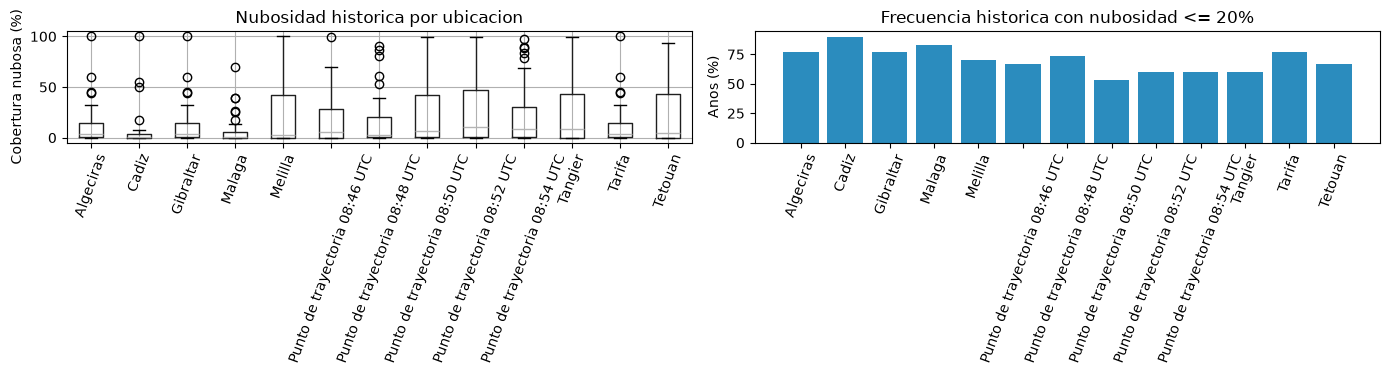

Ubicaciones con >= 15 anos validos: 13


In [28]:
climate_summary = (
    weather_df.groupby("name")
    .agg(
        valid_years=("year", "nunique"),
        mean_cloud_cover_pct=("cloud_cover_pct", "mean"),
        std_cloud_cover_pct=("cloud_cover_pct", "std"),
        clear_probability=("clear_sky_proxy", "mean"),
    )
    .reset_index()
)
climate_summary["clear_probability_pct"] = 100 * climate_summary["clear_probability"]
climate_summary["rankable_climate"] = climate_summary["valid_years"] >= MIN_VALID_YEARS

display(climate_summary.sort_values("clear_probability", ascending=False))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
weather_df.boxplot(column="cloud_cover_pct", by="name", ax=axes[0], rot=70)
axes[0].set_title("Nubosidad historica por ubicacion")
axes[0].set_xlabel("")
axes[0].set_ylabel("Cobertura nubosa (%)")
axes[1].bar(climate_summary["name"], climate_summary["clear_probability_pct"], color="#2b8cbe")
axes[1].set_title("Frecuencia historica con nubosidad <= 20%")
axes[1].set_ylabel("Anos (%)")
axes[1].tick_params(axis="x", rotation=70)
fig.suptitle("")
fig.tight_layout()
plt.show()

climate_columns = ["valid_years", "mean_cloud_cover_pct", "std_cloud_cover_pct", "clear_probability", "clear_probability_pct", "rankable_climate"]
eligible_df = eligible_df.drop(columns=climate_columns + ["nearest_airport", "nearest_airport_km", "access_score"], errors="ignore").merge(climate_summary, on="name", how="left")
print(f"Ubicaciones con >= {MIN_VALID_YEARS} anos validos: {int(eligible_df['rankable_climate'].fillna(False).sum())}")

## 10. Variables geoespaciales y accesibilidad

Se calcula la distancia al aeropuerto mediano/grande mas cercano desde OurAirports. El archivo no garantiza disponibilidad de vuelos ni conectividad terrestre; se filtran aeropuertos del tipo correspondiente y con servicio programado cuando ese campo existe. Tambien se preparan hora, distancia a la linea, duracion estimada y fecha para los modelos exploratorios.

In [29]:
airport_source_available = False
try:
    airport_response = SESSION.get(OURAIRPORTS_URL, timeout=REQUEST_TIMEOUT)
    airport_response.raise_for_status()
    from io import StringIO
    airports = pd.read_csv(StringIO(airport_response.text))
    required_columns = {"type", "latitude_deg", "longitude_deg", "name"}
    if not required_columns.issubset(airports.columns):
        raise ValueError(f"Faltan columnas requeridas: {required_columns - set(airports.columns)}")
    airports = airports.loc[airports["type"].isin(["large_airport", "medium_airport"])].copy()
    if "scheduled_service" in airports.columns:
        airports = airports.loc[airports["scheduled_service"].astype(str).str.lower().eq("yes")]
    airports = airports.dropna(subset=["latitude_deg", "longitude_deg"])
    if airports.empty:
        raise ValueError("No quedan aeropuertos medianos/grandes operativos segun los campos disponibles.")
    airport_source_available = True
except (requests.RequestException, ValueError, pd.errors.ParserError) as error:
    print(f"No se pudo usar OurAirports ({OURAIRPORTS_URL}): {error}")
    airports = pd.DataFrame()


def haversine_km(lat1, lon1, lat2, lon2):
    radius_km = 6371.0088
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    delta_lat, delta_lon = lat2 - lat1, lon2 - lon1
    term = np.sin(delta_lat / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(delta_lon / 2) ** 2
    return 2 * radius_km * np.arcsin(np.sqrt(term))


if airport_source_available:
    nearest_airports = []
    for _, location in eligible_df.iterrows():
        distances = haversine_km(
            location["latitude"], location["longitude"],
            airports["latitude_deg"].to_numpy(), airports["longitude_deg"].to_numpy(),
        )
        nearest_index = int(np.argmin(distances))
        nearest = airports.iloc[nearest_index]
        nearest_airports.append({
            "name": location["name"],
            "nearest_airport": nearest["name"],
            "nearest_airport_km": float(distances[nearest_index]),
        })
    airport_summary = pd.DataFrame(nearest_airports)
    eligible_df = eligible_df.merge(airport_summary, on="name", how="left")
    eligible_df["access_score"] = 1 - (eligible_df["nearest_airport_km"].clip(upper=150) / 150)
else:
    eligible_df["nearest_airport"] = pd.NA
    eligible_df["nearest_airport_km"] = np.nan
    eligible_df["access_score"] = np.nan

display(eligible_df[["name", "estimated_totality_s", "valid_years", "mean_cloud_cover_pct", "nearest_airport", "nearest_airport_km"]].head(15))

# Feature table for exploratory modelling; year is reserved for temporal validation, never a predictor.
training_df = weather_df.merge(
    eligible_df[["name", "estimated_totality_s", "distance_km", "path_width_km"]],
    on="name", how="inner",
)
training_df["event_hour_utc"] = training_df["event_time_utc"].map(
    lambda value: int(value[:2]) + int(value[3:]) / 60.0
)
training_df["day_of_year"] = pd.Timestamp(EVENT_DATE).dayofyear
FEATURES = [
    "latitude", "longitude", "day_of_year", "event_hour_utc",
    "estimated_totality_s", "distance_km", "path_width_km",
]
X = training_df[FEATURES]
y = training_df["clear_sky_proxy"].astype(int)
print(f"Filas de entrenamiento: {len(training_df)}; positivos despejados: {int(y.sum())}")

,name,estimated_totality_s,valid_years,mean_cloud_cover_pct,nearest_airport,nearest_airport_km
0,Tarifa,278.881103,30,13.566667,Gibraltar Airport,27.586247
1,Cadiz,173.307668,30,8.566667,Jerez Airport,31.631563
2,Algeciras,266.629513,30,13.566667,Gibraltar Airport,9.631887
3,Malaga,107.958617,30,8.733333,Málaga-Costa del Sol Airport,8.638353
4,Gibraltar,267.373770,30,13.566667,Gibraltar Airport,1.257380
5,Tangier,290.547010,30,25.633333,Tangier Ibn Battuta Airport,8.475077
6,Tetouan,290.865853,30,21.133333,Sania Ramel Airport,3.896705
7,Melilla,272.792105,30,23.333333,Melilla Airport,2.156123
8,Punto de trayectoria 08:46 UTC,288.300000,30,17.333333,Tangier Ibn Battuta Airport,72.701021
9,Punto de trayectoria 08:48 UTC,293.800000,30,18.233333,Sania Ramel Airport,31.221473


Filas de entrenamiento: 390; positivos despejados: 274


## 11. Baseline y modelos candidatos

Se compara un baseline de clase mayoritaria con regresion logistica y Random Forest. La validacion es temporal: los ultimos anos quedan fuera del entrenamiento. Estas metricas evalúan si las variables espaciales/astronomicas generalizan a anos historicos no vistos; no demuestran que se pueda pronosticar con anos de antelacion el tiempo del evento. La recomendacion principal conserva la frecuencia climatologica empírica por ser mas transparente.

In [30]:
model_metrics = []
model_predictions = pd.DataFrame()
model_artifact_path = None
unique_years = np.sort(training_df["year"].unique())
if len(training_df) >= 60 and len(unique_years) >= 10:
    temporal_cutoff = unique_years[max(1, int(len(unique_years) * 0.8))]
    train_mask = training_df["year"] < temporal_cutoff
    test_mask = ~train_mask
    X_train, X_test = X.loc[train_mask], X.loc[test_mask]
    y_train, y_test = y.loc[train_mask], y.loc[test_mask]
    if y_train.nunique() == 2 and len(X_test) > 0:
        candidate_models = {
            "Baseline frecuencia": make_pipeline(SimpleImputer(strategy="median"), DummyClassifier(strategy="prior")),
            "Regresion logistica": make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=1000, random_state=SEED)),
            "Random Forest": make_pipeline(SimpleImputer(strategy="median"), RandomForestClassifier(n_estimators=300, max_depth=5, min_samples_leaf=4, class_weight="balanced", random_state=SEED)),
        }
        prediction_features = eligible_df.copy()
        prediction_features["day_of_year"] = pd.Timestamp(EVENT_DATE).dayofyear
        prediction_features["event_hour_utc"] = prediction_features["time_utc_min"] / 60.0
        for model_name, pipeline in candidate_models.items():
            pipeline.fit(X_train, y_train)
            test_predictions = pipeline.predict(X_test)
            probabilities = pipeline.predict_proba(X_test)[:, 1] if len(pipeline.classes_) > 1 else np.zeros(len(X_test))
            metrics = {
                "modelo": model_name,
                "train_hasta_ano": int(training_df.loc[train_mask, "year"].max()),
                "test_desde_ano": int(temporal_cutoff),
                "n_test": int(test_mask.sum()),
                "accuracy": accuracy_score(y_test, test_predictions),
                "f1": f1_score(y_test, test_predictions, zero_division=0),
                "roc_auc": roc_auc_score(y_test, probabilities) if y_test.nunique() == 2 else np.nan,
            }
            model_metrics.append(metrics)
            if model_name != "Baseline frecuencia":
                output = prediction_features[["name"]].copy()
                output[f"prob_clear_{model_name.lower().replace(' ', '_')}"] = pipeline.predict_proba(prediction_features[FEATURES])[:, 1]
                model_predictions = output if model_predictions.empty else model_predictions.merge(output, on="name", how="outer")
        # Keep the Random Forest pipeline for reproducibility; predictions remain exploratory.
        import joblib
        model_dir = PROJECT_ROOT / "models"
        model_dir.mkdir(parents=True, exist_ok=True)
        model_artifact_path = model_dir / f"clear_sky_rf_{EVENT_DATE}.joblib"
        joblib.dump(candidate_models["Random Forest"], model_artifact_path)
    else:
        print("No se entrenan modelos: la particion temporal de entrenamiento no contiene ambas clases.")
else:
    print("No se entrenan modelos: hacen falta al menos 60 observaciones y 10 anos validos.")

model_metrics_df = pd.DataFrame(model_metrics)
if not model_metrics_df.empty:
    display(model_metrics_df.sort_values("roc_auc", ascending=False, na_position="last"))
    display(model_predictions)
    model_predictions.to_csv(RAW_DATA_DIR / f"model_predictions_{EVENT_DATE}.csv", index=False)
    print(f"Modelo Random Forest serializado: {model_artifact_path}")

,modelo,train_hasta_ano,test_desde_ano,n_test,accuracy,f1,roc_auc
1,Regresion logistica,2020,2021,78,0.500000,0.561798,0.564228
2,Random Forest,2020,2021,78,0.525641,0.610526,0.542819
0,Baseline frecuencia,2020,2021,78,0.756410,0.861314,0.500000


,name,prob_clear_regresion_logistica,prob_clear_random_forest
0,Algeciras,0.583194,0.590909
1,Cadiz,0.733774,0.740647
2,Gibraltar,0.580698,0.588870
3,Malaga,0.766502,0.764140
4,Melilla,0.434041,0.438008
5,Punto de trayectoria 08:46 UTC,0.461008,0.423552
6,Punto de trayectoria 08:48 UTC,0.438456,0.565402
7,Punto de trayectoria 08:50 UTC,0.413007,0.366442
8,Punto de trayectoria 08:52 UTC,0.385237,0.315947
9,Punto de trayectoria 08:54 UTC,0.355969,0.430608


Modelo Random Forest serializado: e:\Programming\Master\Proyecto_TFM\models\clear_sky_rf_2027-08-02.joblib


## 12. Validar errores y construir el ranking

La comparacion de modelos incluye accuracy, F1 y ROC-AUC cuando hay ambas clases en el periodo de prueba. Se revisan errores por ubicacion e importancia de variables. El score final combina probabilidad climatologica de cielo despejado, duracion de totalidad y acceso; si falta una fuente, redistribuye el peso entre los componentes disponibles. La sensibilidad compara tres conjuntos de pesos razonables.

,count,mean
name,,
Melilla,6,1.000000
Punto de trayectoria 08:52 UTC,6,1.000000
Punto de trayectoria 08:46 UTC,6,0.833333
Tetouan,6,0.666667
Punto de trayectoria 08:50 UTC,6,0.500000
Tangier,6,0.500000
Punto de trayectoria 08:54 UTC,6,0.500000
Punto de trayectoria 08:48 UTC,6,0.333333
Malaga,6,0.333333


,importance
estimated_totality_s,0.237199
latitude,0.219373
distance_km,0.177968
longitude,0.148751
path_width_km,0.129643
event_hour_utc,0.087065
day_of_year,0.000000


Pesos activos, renormalizados si falta alguna fuente:
{'clear_probability': 0.55, 'duration_score': 0.3, 'access_score': 0.15}


,name,score,clear_probability_pct,estimated_totality_s,distance_km,nearest_airport,nearest_airport_km
0,Gibraltar,0.829995,76.666667,267.373770,48.235685,Gibraltar Airport,1.257380
1,Algeciras,0.820898,76.666667,266.629513,48.624146,Gibraltar Airport,9.631887
2,Tarifa,0.814839,76.666667,278.881103,34.998208,Gibraltar Airport,27.586247
3,Punto de trayectoria 08:48 UTC,0.807355,73.333333,293.800000,0.000000,Sania Ramel Airport,31.221473
4,Melilla,0.797691,70.000000,272.792105,49.994045,Melilla Airport,2.156123
5,Tetouan,0.795164,66.666667,290.865853,13.044699,Sania Ramel Airport,3.896705
6,Cadiz,0.781628,90.000000,173.307668,94.692231,Jerez Airport,31.631563
7,Tangier,0.753609,60.000000,290.547010,7.693314,Tangier Ibn Battuta Airport,8.475077
8,Punto de trayectoria 08:54 UTC,0.751835,60.000000,309.000000,0.000000,Oran Es-Sénia (Ahmed Ben Bella) International ...,28.164661
9,Punto de trayectoria 08:46 UTC,0.723869,66.666667,288.300000,0.000000,Tangier Ibn Battuta Airport,72.701021



Ubicacion recomendada para inspeccion logistica: Gibraltar


,escenario,primera_opcion,top_3
0,base,Gibraltar,"Gibraltar, Algeciras, Tarifa"
1,prioridad_clima,Cadiz,"Cadiz, Gibraltar, Algeciras"
2,prioridad_acceso,Gibraltar,"Gibraltar, Algeciras, Melilla"


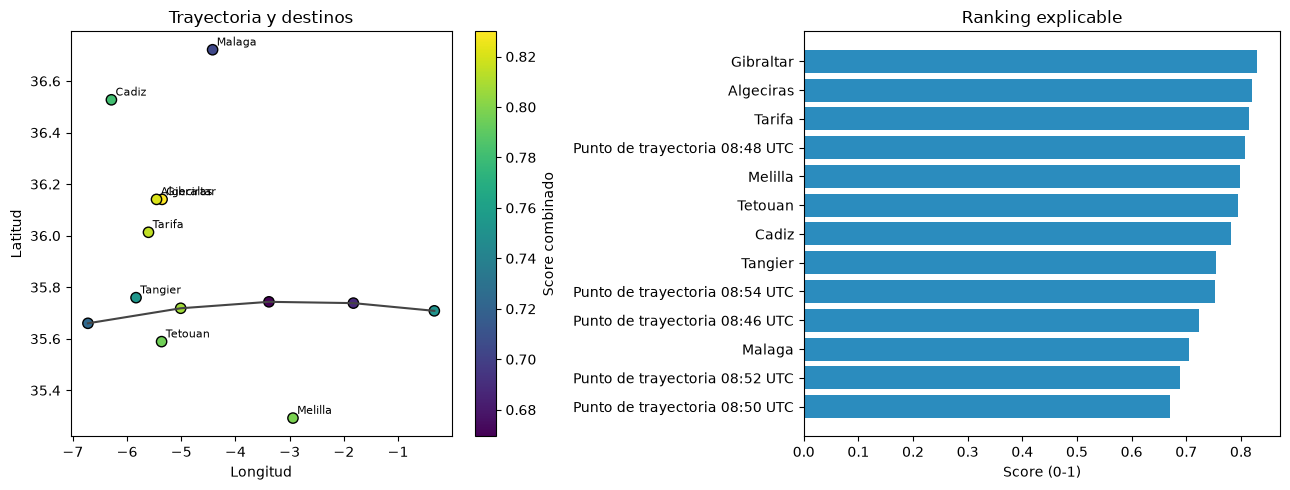

In [31]:
if not model_metrics_df.empty:
    rf_pipeline = candidate_models["Random Forest"]
    validation_predictions = rf_pipeline.predict(X_test)
    error_review = training_df.loc[test_mask, ["year", "name", "clear_sky_proxy"]].copy()
    error_review["predicted_clear"] = validation_predictions
    error_review["absolute_error"] = (error_review["clear_sky_proxy"] - error_review["predicted_clear"]).abs()
    display(error_review.groupby("name")["absolute_error"].agg(["count", "mean"]).sort_values("mean", ascending=False))
    classifier = rf_pipeline.named_steps["randomforestclassifier"]
    feature_importance = pd.Series(classifier.feature_importances_, index=FEATURES, name="importance").sort_values(ascending=False)
    display(feature_importance.to_frame())
else:
    print("Sin conjunto de prueba suficiente para analizar errores o importancia de variables.")

scored_candidates = eligible_df.loc[
    eligible_df["rankable_climate"].fillna(False)
].copy()
if scored_candidates.empty:
    raise RuntimeError(f"No hay ubicaciones con al menos {MIN_VALID_YEARS} anos de climatologia.")
scored_candidates["duration_score"] = (
    scored_candidates["estimated_totality_s"] / scored_candidates["estimated_totality_s"].max()
).clip(0, 1)
BASE_WEIGHTS = {"clear_probability": 0.55, "duration_score": 0.30, "access_score": 0.15}


def weighted_score(row, weights):
    available = {key: value for key, value in weights.items() if pd.notna(row.get(key))}
    total_weight = sum(available.values())
    return sum(row[key] * weight for key, weight in available.items()) / total_weight if total_weight else np.nan


scored_candidates["score"] = scored_candidates.apply(weighted_score, axis=1, weights=BASE_WEIGHTS)
scored_candidates = scored_candidates.sort_values("score", ascending=False).reset_index(drop=True)
recommended_site = scored_candidates.iloc[0]
active_keys = [key for key in BASE_WEIGHTS if scored_candidates[key].notna().any()]
active_total = sum(BASE_WEIGHTS[key] for key in active_keys)
print("Pesos activos, renormalizados si falta alguna fuente:")
print({key: round(BASE_WEIGHTS[key] / active_total, 3) for key in active_keys})
display(scored_candidates[["name", "score", "clear_probability_pct", "estimated_totality_s", "distance_km", "nearest_airport", "nearest_airport_km"]])
print(f"\nUbicacion recomendada para inspeccion logistica: {recommended_site['name']}")

sensitivity_weights = {
    "base": BASE_WEIGHTS,
    "prioridad_clima": {"clear_probability": 0.70, "duration_score": 0.20, "access_score": 0.10},
    "prioridad_acceso": {"clear_probability": 0.40, "duration_score": 0.20, "access_score": 0.40},
}
sensitivity = []
for scenario, weights in sensitivity_weights.items():
    order = scored_candidates.assign(
        scenario_score=scored_candidates.apply(weighted_score, axis=1, weights=weights)
    ).sort_values("scenario_score", ascending=False)
    sensitivity.append({"escenario": scenario, "primera_opcion": order.iloc[0]["name"], "top_3": ", ".join(order.head(3)["name"].tolist())})
display(pd.DataFrame(sensitivity))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
regional_path = path_df.loc[
    path_df["latitude"].between(south, north) & path_df["longitude"].between(west, east)
]
axes[0].plot(regional_path["longitude"], regional_path["latitude"], color="#444444", linewidth=1.5, label="Linea central NASA")
scatter = axes[0].scatter(scored_candidates["longitude"], scored_candidates["latitude"], c=scored_candidates["score"], cmap="viridis", s=55, edgecolor="black")
for _, location in scored_candidates.loc[scored_candidates["candidate_type"] == "destino"].iterrows():
    axes[0].annotate(location["name"], (location["longitude"], location["latitude"]), fontsize=8, xytext=(3, 3), textcoords="offset points")
axes[0].set(xlabel="Longitud", ylabel="Latitud", title="Trayectoria y destinos")
fig.colorbar(scatter, ax=axes[0], label="Score combinado")
axes[1].barh(scored_candidates["name"], scored_candidates["score"], color="#2b8cbe")
axes[1].invert_yaxis()
axes[1].set(xlabel="Score (0-1)", title="Ranking explicable")
fig.tight_layout()
plt.show()

## 13. Alojamiento, rutas y exportacion

Para el primer destino del ranking se consultan alojamientos etiquetados en OpenStreetMap dentro del radio configurado. La consulta localiza POI, pero no confirma disponibilidad, precio, calidad ni permisos. Si se indica `ORIGIN`, OSRM calcula una ruta de conduccion de demostracion hasta el punto de observacion; los servicios publicos tienen limites y no sustituyen a una ruta operativa validada.

In [ ]:
selected_lat = float(recommended_site["latitude"])
selected_lon = float(recommended_site["longitude"])
selected_name = str(recommended_site["name"])
radius = int(HOTEL_SEARCH_RADIUS_M)
overpass_query = f"""
[out:json][timeout:20];
(
  nwr(around:{radius},{selected_lat},{selected_lon})["tourism"~"^(hotel|hostel|guest_house|motel)$"];
);
out center tags;
"""
overpass_endpoints = [OVERPASS_URL, "https://overpass.kumi.systems/api/interpreter"]
lodging_records = []
overpass_errors = []
for endpoint in overpass_endpoints:
    try:
        overpass_response = SESSION.post(
            endpoint, data={"data": overpass_query}, timeout=REQUEST_TIMEOUT
        )
        overpass_response.raise_for_status()
        elements = overpass_response.json().get("elements", [])
        for element in elements:
            tags = element.get("tags", {})
            point = element.get("center", element)
            if "lat" not in point or "lon" not in point:
                continue
            lodging_records.append({
                "name": tags.get("name", "Alojamiento sin nombre"),
                "type": tags.get("tourism", "unknown"),
                "latitude": float(point["lat"]),
                "longitude": float(point["lon"]),
                "distance_to_observation_km": float(haversine_km(
                    selected_lat, selected_lon, float(point["lat"]), float(point["lon"])
                )),
                "osm_type": element.get("type"),
                "osm_id": element.get("id"),
            })
        break
    except (requests.RequestException, ValueError, KeyError) as error:
        overpass_errors.append(f"{endpoint}: {error}")

lodging_df = pd.DataFrame(lodging_records)
if not lodging_df.empty:
    lodging_df = lodging_df.drop_duplicates("osm_id").sort_values("distance_to_observation_km")
    lodging_file = RAW_DATA_DIR / f"lodging_near_{EVENT_DATE}.csv"
    lodging_df.to_csv(lodging_file, index=False)
    display(lodging_df.head(20))
else:
    print("No se pudo obtener alojamiento en Overpass:")
    print("\n".join(overpass_errors))
    print("Revisa conectividad, radio y cobertura de OpenStreetMap.")

route_result = None
if ORIGIN is not None:
    origin_lat = float(ORIGIN["latitude"])
    origin_lon = float(ORIGIN["longitude"])
    route_url = f"{OSRM_URL}/{origin_lon},{origin_lat};{selected_lon},{selected_lat}"
    route_response = SESSION.get(route_url, params={"overview": "false", "steps": "false"}, timeout=REQUEST_TIMEOUT)
    route_response.raise_for_status()
    route_payload = route_response.json()
    if route_payload.get("code") != "Ok" or not route_payload.get("routes"):
        raise RuntimeError(f"OSRM no encontro ruta: {route_payload.get('message', route_payload.get('code'))}")
    route_result = route_payload["routes"][0]
    print(f"Ruta desde ORIGIN hasta {selected_name}: {route_result['distance'] / 1000:.1f} km, {route_result['duration'] / 3600:.1f} h (OSRM/OSM).")
else:
    print("ORIGIN no configurado: define latitud/longitud para calcular una ruta desde tu punto de partida.")

ranking_file = PROJECT_ROOT / "data" / f"eclipse_recommendations_{EVENT_DATE}.csv"
ranking_file.parent.mkdir(parents=True, exist_ok=True)
scored_candidates.to_csv(ranking_file, index=False)
recommendation_metadata = {
    "event_date": EVENT_DATE,
    "path_source": ECLIPSE_PATH_URL,
    "recommended_location": selected_name,
    "score_weights": BASE_WEIGHTS,
    "weather_interpretation": "historical climatology, not an event forecast",
    "lodging_source": overpass_endpoints,
    "route_source": OSRM_URL if ORIGIN is not None else None,
    "created_utc": pd.Timestamp.now(tz="UTC").isoformat(),
}
pd.Series(recommendation_metadata).to_json(
    ranking_file.with_suffix(".metadata.json"), indent=2
)
print(f"Ranking exportado a {ranking_file}")

No se pudo obtener alojamiento en Overpass:
https://overpass-api.de/api/interpreter: 504 Server Error: Gateway Timeout for url: https://overpass-api.de/api/interpreter
https://overpass.kumi.systems/api/interpreter: HTTPSConnectionPool(host='overpass.kumi.systems', port=443): Read timed out. (read timeout=45)
Revisa conectividad, radio y cobertura de OpenStreetMap.
ORIGIN no configurado: define latitud/longitud para calcular una ruta desde tu punto de partida.
Ranking exportado a e:\Programming\Master\Proyecto_TFM\data\eclipse_recommendations_2027-08-02.csv


: 

### Interpretacion y siguiente version

La primera opcion solo es la mejor bajo los pesos y fuentes seleccionados. En el ejemplo Iberico, cambiar el peso de clima frente a acceso ya puede cambiar el destino ganador. El baseline climatologico debe prevalecer sobre modelos que no superen una validacion temporal convincente; los resultados de ML son exploratorios y no pronosticos del dia del eclipse.

Para reutilizar el notebook, cambia `EVENT_DATE`, `ECLIPSE_PATH_URL`, `REGION_BOUNDS` y la lista `CANDIDATE_PLACES`; ejecuta las celdas en orden. Para planificar el viaje, configura `ORIGIN`, revisa disponibilidad real de alojamiento/transporte y actualiza la decision con pronosticos meteorologicos oficiales poco antes del evento. Una version de producto deberia incorporar disponibilidad/precio con fuentes autorizadas, rutas de transporte publico, carreteras y accesibilidad, elevacion/horizonte y restricciones locales.

### Fuentes y atribucion

- NASA GSFC, trayectoria del eclipse seleccionado: https://eclipse.gsfc.nasa.gov/SEpath/SEpath2001/SE2027Aug02Tpath.html. Atribucion de esta tabla: **Eclipse Predictions by Fred Espenak, NASA's GSFC**. Cambia la URL para consultar otro eclipse.
- NASA GSFC, catalogos de eclipses: https://eclipse.gsfc.nasa.gov/SEcat5/SEcatalog.html
- US Naval Observatory, datos de eclipses: https://aa.usno.navy.mil/data/Eclipse
- Open-Meteo Historical Weather API: https://open-meteo.com/en/docs/historical-weather-api. Cita recomendada: Zippenfenig, P. (2023), *Open-Meteo.com Weather API*, https://doi.org/10.5281/zenodo.7970649. Datos de reanalisis ERA5, ECMWF: https://doi.org/10.24381/cds.adbb2d47. Verifica terminos de Open-Meteo antes de uso comercial.
- OurAirports, datos abiertos de aeropuertos: https://github.com/davidmegginson/ourairports-data. El aerodromo mas cercano no implica vuelos, conexiones o disponibilidad.
- OpenStreetMap, alojamientos y red vial: https://www.openstreetmap.org/copyright. Datos bajo ODbL; Overpass API: https://overpass-api.de/; OSRM demo: https://project-osrm.org/. Respetar atribucion, licencias, politica de uso y limites de los servicios.